For the selection and implemention of quantum data encoding technique on the non-normalised but transformed dataset

In [3]:
import sys
!conda install --yes --prefix {sys.prefix} numpy
!conda install --yes --prefix {sys.prefix} matplotlib
!conda install --yes --prefix {sys.prefix} pandas
!conda install --yes --prefix {sys.prefix} tensorflow
!conda install --yes --prefix {sys.prefix} scikit-learn
!conda install --yes --prefix {sys.prefix} qiskit
!conda install --yes --prefix {sys.prefix} qiskit-machine-learning

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: \ 

# All requested packages already installed.

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json): - 
doneing environment: / 

# All requested packages already installed.

Jupyter detected...
2 channel Terms of Service accepted
Channels:
 - defaults
Platform: linux-64
doneecting package metadata (repodata.json)

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import tensorflow as tf
from math import pi
import time

from sklearn.preprocessing import MinMaxScaler
from qiskit import QuantumCircuit
from qiskit import QuantumRegister, ClassicalRegister
from qiskit.quantum_info import Statevector
from qiskit.circuit.library import efficient_su2, real_amplitudes
from qiskit_machine_learning.neural_networks import SamplerQNN
from qiskit.primitives import StatevectorSampler as Sampler
from qiskit_machine_learning.optimizers import COBYLA
from qiskit_machine_learning.utils import algorithm_globals

import tensorflow as tf
from keras import layers

algorithm_globals.random_seed = 42
sampler = Sampler()


2025-07-17 16:43:46.293934: I tensorflow/core/util/port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
2025-07-17 16:43:46.317820: I tensorflow/core/platform/cpu_feature_guard.cc:210] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: SSE4.1 SSE4.2 AVX AVX2 AVX512F AVX512_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


Before we proceed we first need to reduce the dimensions. Our dataset has 24 features so we reduce it to 8 using a modified version of the Autoencoder we previously built.

In [2]:
@tf.keras.utils.register_keras_serializable()
class AnomalyDetector(tf.keras.Model):
    def __init__(self, **kwargs):
        super(AnomalyDetector, self).__init__(**kwargs)
        self.encoder = tf.keras.Sequential([
          # layers.Dense(16, activation="relu"),
          # # Model was overfitting so add dropout layers
          # layers.Dropout(0.2),
          # layers.Dense(8, activation="relu"),
          # layers.Dropout(0.2),
          # layers.Dense(4, activation="relu")

            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(8, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU()
        ])
    
        self.decoder = tf.keras.Sequential([

            layers.Dense(16, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dropout(0.1),
            layers.Dense(32, activation=None),
            layers.BatchNormalization(),
            layers.LeakyReLU(),
            layers.Dense(24)
            
          # layers.Dense(8, activation="relu"),
          # layers.Dropout(0.2),
          # layers.Dense(16, activation="relu"),
          # layers.Dropout(0.1),
          # layers.Dense(24)
        ])
      
    def call(self, x):
        encoded = self.encoder(x)
        decoded = self.decoder(encoded)
        return decoded

    def get_config(self):
        # Return config dictionary; empty because no constructor args
        base_config = super(AnomalyDetector, self).get_config()
        return base_config

    @classmethod
    def from_config(cls, config):
        return cls(**config)


autoencoder = AnomalyDetector()

In [3]:
autoencoder_model = tf.keras.models.load_model(
    "Models/feature_reduction_autoencoder_model.keras",
    custom_objects={"AnomalyDetector": AnomalyDetector}
)

In [4]:
transformed_training_data = pd.read_csv('Dataset/Transformed/Normalised/labelled_transformed_training_data.csv')

# 1. Extract labels (column 6)
training_labels = transformed_training_data.iloc[:, 6].astype(bool)  # Anomalies: True

# 2. Drop label and extra column (column 6 and 7)
training_data = transformed_training_data.drop(
    columns=[transformed_training_data.columns[6], transformed_training_data.columns[7]]
)

# 3. Convert to float32 tensor
training_data = tf.convert_to_tensor(training_data.values, dtype=tf.float32)

# 4. Convert labels to tensor (bool)
training_labels = tf.convert_to_tensor(training_labels.values, dtype=tf.bool)

# 5. Split normal vs anomalous
normal_training_data = tf.boolean_mask(training_data, ~training_labels)
anomalous_training_data = tf.boolean_mask(training_data, training_labels)

In [5]:
# Pass both normal and anomalous data through the autoencoder
reconstructed_normal = autoencoder(normal_training_data).numpy()
reconstructed_anomalous = autoencoder(anomalous_training_data).numpy()

# Compute sample-wise MAE (Mean Absolute Error)
mae_normal = np.mean(np.abs(normal_training_data.numpy() - reconstructed_normal), axis=1)
mae_anomalous = np.mean(np.abs(anomalous_training_data.numpy() - reconstructed_anomalous), axis=1)

# Print statistics
print("Normal MAE: Mean =", np.mean(mae_normal), ", Std =", np.std(mae_normal))
print("Anomalous MAE: Mean =", np.mean(mae_anomalous), ", Std =", np.std(mae_anomalous))


Normal MAE: Mean = 0.18802907 , Std = 0.04042567
Anomalous MAE: Mean = 0.30755872 , Std = 0.07532397


Now we can reduce to 8 features and scale it

In [6]:
reduced_normal_training_data = autoencoder.encoder(normal_training_data)

n_qubits = reduced_normal_training_data.shape[1]
n_samples = 5000  # For speed/testing

# --- SCALE TO [0, 2π] ---
scaler = MinMaxScaler(feature_range=(0, 2 * np.pi))
scaled_normal_training_encoded = scaler.fit_transform(reduced_normal_training_data)

Considering that our dataset consist of mostly categorical features of no particular inherent order, we determine what might be the best method of encoding. Here we factory in traditional quantum data encoding methods as well as built-in feature maps from Qiskit.

Immediately, we rule out Basis Encoding (due to its discrete/binary nature) and Amplitude Encoding (due to the relevance of magnitude and hence order).

We would want to pick something that is ideally non-linear in nature. This is to emphasise the relationships between categorical features and for anomaly detection.

Also we want to rule out feature maps that could be classically computationally expensive due to the limitations of the hardware the simulations are runned on.

Therefore, we are mainly left to consider Dense Angle Encoding and a built-in Qiskit feature map EfficientSU2.

To decide we can evaluate empirically to determine what method would be best before proceeding.

We will evaluate its expressiveness and computational time.

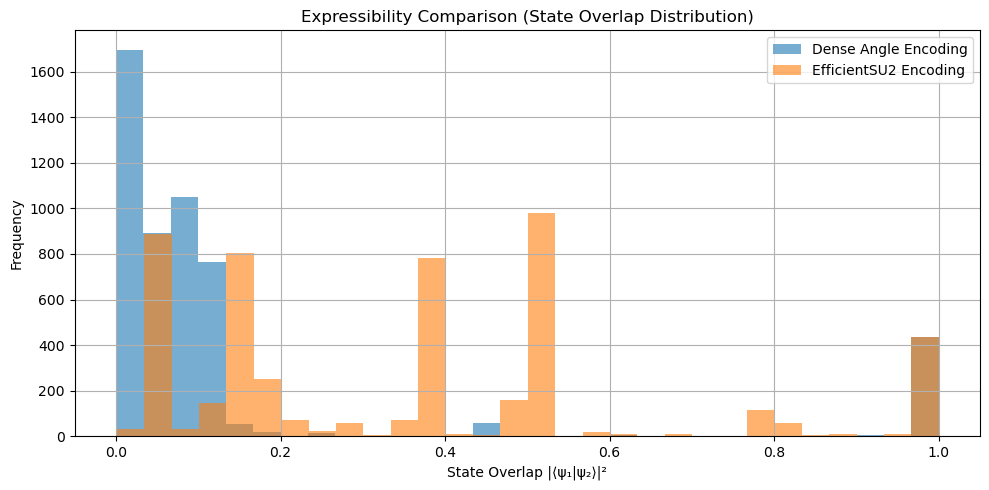

  Avg Dense Circuit Time (s): 0.001442
  Avg SU2 Circuit Time (s): 0.001477


In [7]:
# --- ENCODING CIRCUITS ---
def dense_angle_encoding(params):
    qc = QuantumCircuit(n_qubits)
    for i in range(n_qubits):
        qc.ry(params[i], i)
        qc.rz(params[i + n_qubits], i)
    return qc

def efficient_su2_encoding(params):
    template = efficient_su2(num_qubits=2, reps=1, insert_barriers=True, entanglement='linear')
    param_dict = dict(zip(template.parameters, params))
    return template.assign_parameters(param_dict)

# --- EXPRESSIBILITY METRIC ---
def compute_expressibility(circuit_builder, param_count, input_data):
    overlaps = []
    times = []

    for i in range(n_samples):
        idx1 = i % len(input_data)
        idx2 = (i + 1) % len(input_data)

        params1 = input_data[idx1]
        params2 = input_data[idx2]

        start = time.time()
        sv1 = Statevector.from_instruction(circuit_builder(params1)).data
        sv2 = Statevector.from_instruction(circuit_builder(params2)).data
        end = time.time()

        overlap = np.abs(np.vdot(sv1, sv2))**2
        overlaps.append(overlap)
        times.append(end - start)

    return np.array(overlaps), np.mean(times)

# --- RUN TESTS ---
dense_data = np.array([np.concatenate([row, row]) for row in scaled_normal_training_encoded])
dense_overlaps, dense_avg_time = compute_expressibility(dense_angle_encoding, 2 * n_qubits, dense_data)

su2_param_count = efficient_su2(num_qubits=n_qubits, reps=1).num_parameters
su2_data = np.array([row[:su2_param_count] for row in scaled_normal_training_encoded])
su2_overlaps, su2_avg_time = compute_expressibility(efficient_su2_encoding, su2_param_count, su2_data)

# --- PLOT ---
plt.figure(figsize=(10, 5))
plt.hist(dense_overlaps, bins=30, alpha=0.6, label="Dense Angle Encoding")
plt.hist(su2_overlaps, bins=30, alpha=0.6, label="EfficientSU2 Encoding")
plt.title("Expressibility Comparison (State Overlap Distribution)")
plt.xlabel("State Overlap |⟨ψ₁|ψ₂⟩|²")
plt.ylabel("Frequency")
plt.legend()
plt.grid(True)
plt.tight_layout()
plt.show()

print(f"  Avg Dense Circuit Time (s): {dense_avg_time:.6f}")
print(f"  Avg SU2 Circuit Time (s): {su2_avg_time:.6f}")

Let's go with EfficientSU2 as there does not seem to be drastically different computation times for data loading.

Additionally, it has a better spread. Dense seems to represent everything quite distinctly which may be good but may falsely mean every single datapoint is vastly distinct.

In [9]:
encoding_circuit = efficient_su2(num_qubits=2, reps=1, insert_barriers=True, entanglement='linear', parameter_prefix='i')
# su2_normal_training_data = np.array([row[:su2_param_count] for row in scaled_normal_training_encoded])
# normal_training_qencoded = [encoding_circuit.assign_parameters(sample_params) for sample_params in su2_normal_training_data]

In [10]:
def ansatz(num_qubits):
    return real_amplitudes(num_qubits, reps=5)

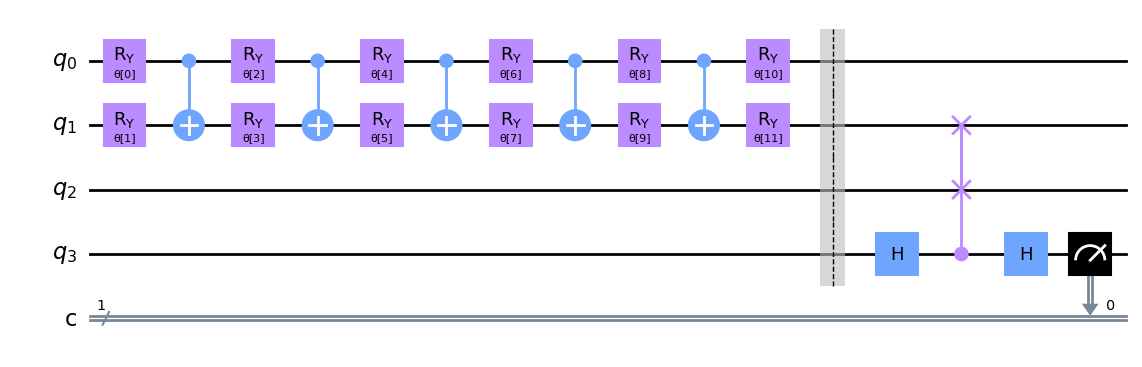

In [11]:
def auto_encoder_circuit(num_latent, num_trash):
    qr = QuantumRegister(num_latent + 2 * num_trash + 1, "q")
    cr = ClassicalRegister(1, "c")
    circuit = QuantumCircuit(qr, cr)
    circuit.compose(ansatz(num_latent + num_trash), range(0, num_latent + num_trash), inplace=True)
    circuit.barrier()
    auxiliary_qubit = num_latent + 2 * num_trash
    # swap test
    circuit.h(auxiliary_qubit)
    for i in range(num_trash):
        circuit.cswap(auxiliary_qubit, num_latent + i, num_latent + num_trash + i)

    circuit.h(auxiliary_qubit)
    circuit.measure(auxiliary_qubit, cr[0])
    return circuit


num_latent = 1
num_trash = 1
circuit = auto_encoder_circuit(num_latent, num_trash)
circuit.draw(output="mpl", style="clifford")

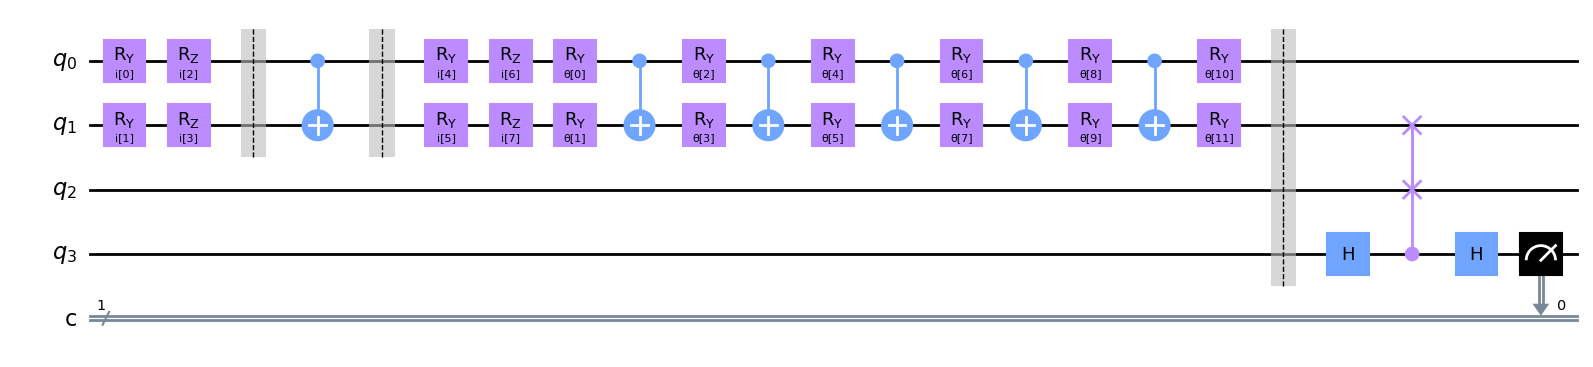

In [12]:
ae = auto_encoder_circuit(num_latent, num_trash)

qc = QuantumCircuit(num_latent + 2 * num_trash + 1, 1)
qc = qc.compose(encoding_circuit, range(num_latent + num_trash))
qc = qc.compose(ae)

qc.draw(output="mpl", style="clifford")

In [13]:
def identity_interpret(x):
    return x


qnn = SamplerQNN(
    circuit=qc,
    input_params=encoding_circuit.parameters,
    weight_params=ae.parameters,
    interpret=identity_interpret,
    output_shape=2,
    sampler=sampler,
)

No gradient function provided, creating a gradient function. If your Sampler requires transpilation, please provide a pass manager.
